# Predictive maintenance with a transformer forecaster: which statistic to use

**Starting question.** Timestral forecasts a machine's sensors. How do you turn the
*predicted vs measured* comparison into a failure alarm? Which mathematical function of the
error should you choose, and over which window should you compute it?

**Short answer, demonstrated in this notebook.** Don't use the raw error, and don't
normalize it by the model's sigma: the forecaster **chases** slow degradation and erases it
from the residual. The solution that works has two stages:

1. **anchor to a frozen reference** (the statistics of the healthy machine, measured at
   commissioning), not to the forecast;
2. **integrate the residual** with a CUSUM or EWMA carried **from window to window**, per sensor.

The numbers behind this claim are produced here, not quoted: ~30 run-to-failure
machines, real forecasts from the 209M model, and three families of statistics compared
at the same false-alarm threshold.

| section | what it establishes |
|---|---|
| 1–2 | the synthetic machine and the fault, with known ground truth |
| 3 | the forecast and the residual: what you see by eye |
| 4 | per-window statistics: **all weak** (AUC 0.5–0.7) |
| 5 | **the chasing problem**: the residual does not move |
| 6 | correct standardization: quantiles, sigma, PIT, calibration |
| 7 | sequential detectors: the math |
| 8 | state carried across windows: **0.96 drift, 1.00 step, but 0.59 variance** |
| 9 | frozen reference: **0.90 drift, 0.95 variance** — the complementary branch |
| 10 | the threshold: split-conformal **per machine**, not per step |
| 11 | the complete algorithm on one machine |

> **Review note (added in translation).** The translation changes the text. The code has three small
changes: file paths for this project's folder layout (section 1), the cache location (section 4),
and a bug fix in section 9. The notebook was re-run on this machine on 18 Nov 2026: every result
matches the original run except the "gain" rows in section 9, which changed with the fix. Notes
like this one point out where the text and the results disagree, or where the code has a problem.
In particular: the fleet is **32 machines, of which only 12 run to failure** (4 per fault mode);
the other 20 are healthy.

## 1. Setup

The model is local: `config.json` and `model.safetensors` are in the repo root and are
loaded with `from_pretrained(".")`. **Hugging Face is not reachable** from this machine,
so no code path tries to download it.

The detector math lives in [`predictive_maintenance/pdm.py`](predictive_maintenance/pdm.py);
the notebook calls it and shows it, so every formula can be checked in the source.

> **Review note (added in translation).** In this copy the notebook lives in `notebooks/`. It finds the project
root by walking up to the folder that contains `models/`, imports
`predictive_maintenance/pdm.py` from there, and loads the model from `models/Timestral-209M`
(Hugging Face is not needed). Use the **Python (timestral)** kernel; `pdm.py` needs scipy, which
is installed in that environment.

In [1]:
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models").is_dir())  # project root
sys.path.insert(0, str(ROOT))

from predictive_maintenance.pdm import (
    MODES,
    PERIOD,
    _interp_quantile,
    auc,
    make_run_to_failure,
    pit_z,
    score_windows,
    sigma_from_quantiles,
    standardize,
    threshold_at_far,
)

MODEL_PATH = ROOT / "models" / "Timestral-209M"  # local copy of the weights
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")
print("fault modes:", MODES, "| cycle period:", PERIOD)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "axes.titlelocation": "left", "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})
BLUE, ORANGE, GREEN, RED, GREY, BAND = "#2a78d6", "#eb6834", "#2e8b57", "#c0392b", "#52514e", "#9ec5f4"

torch 2.14.1+cu126 | GPU: NVIDIA GeForce GTX 1650
fault modes: ('none', 'drift', 'variance', 'step') | cycle period: 96


## 2. The machine and the fault

We need a test bench with **true labels**: a generative model that produces healthy
machines and machines that die, knowing exactly when the fault begins.

The three sensors are those of the multivariate example: `power` with a duty cycle of period 96,
`temperature` that follows `power` with a **16-step lag**, `vibration` proportional to `power`
plus noise. A **slow random walk** is added to every machine, healthy or damaged: it is the
disturbance that makes any fixed threshold on the raw error useless, and forces
normalization.

The three fault modes are the classic signatures from the literature:

| mode | physical signature | where it shows up |
|---|---|---|
| `drift` | friction/wear: the temperature-on-power gain rises | temperature |
| `variance` | mechanical play: vibration jitter grows, the mean does not | vibration |
| `step` | breakage: a level step on power at 3/4 of the life | power |

Note the difficulty: `drift` and `variance` are **slow** and develop over ~1500 steps, while
the forecast window covers 96. This is exactly the point that will decide the answer.

In [2]:
NAMES = ["power", "temperature", "vibration"]
LAG = 16

# Benchmark geometry. LENGTH is the machine life; the model is asked to forecast HORIZON steps
# from every STRIDE-th origin inside the scored region, which starts after CONTEXT steps so the
# first origin already has a usable history.
LENGTH, CONTEXT, HORIZON, STRIDE = 1536, 768, 96, 96
N_HEALTHY, N_PER_MODE = 20, 4          # >= 1/FAR healthy machines are needed to set a 5% threshold
WARNING_BAND = 0.60                    # a window counts as a true positive past 60% of life
ORIGINS = np.arange(CONTEXT, LENGTH - HORIZON + 1, STRIDE)
N_WIN = len(ORIGINS)
print(f"{N_WIN} windows per machine, at steps {ORIGINS[0]}..{ORIGINS[-1]} of {LENGTH}")


def fleet():
    """Healthy machines first, then one block per fault mode. Deterministic: seeds are fixed."""
    data, mode = [], []
    for s in range(N_HEALTHY):
        data.append(make_run_to_failure(LENGTH, seed=s, mode="none"))
        mode.append(-1)
    for m, name in enumerate(MODES[1:]):
        for s in range(N_PER_MODE):
            data.append(make_run_to_failure(LENGTH, seed=1000 + 100 * m + s, mode=name))
            mode.append(m)
    return np.stack(data), np.array(mode)


DATA, MMODE = fleet()
print(f"fleet: {DATA.shape[0]} machines x {DATA.shape[2]} steps | "
      f"{(MMODE < 0).sum()} healthy, {(MMODE >= 0).sum()} run-to-failure")

8 windows per machine, at steps 768..1440 of 1536


fleet: 32 machines x 1536 steps | 20 healthy, 12 run-to-failure


### The three signatures compared

Each column is a fault mode, each row a sensor. The dashed black line is a
healthy machine. Notice how little `drift` and `variance` can be seen by eye on the raw signal:
the degradation is buried in the random walk that healthy machines **also** have.

> **Review note (added in translation).** In the figure the healthy reference is drawn as a thin **grey solid**
line, not a dashed black one. The first column (`none`) shows a healthy machine in solid black.

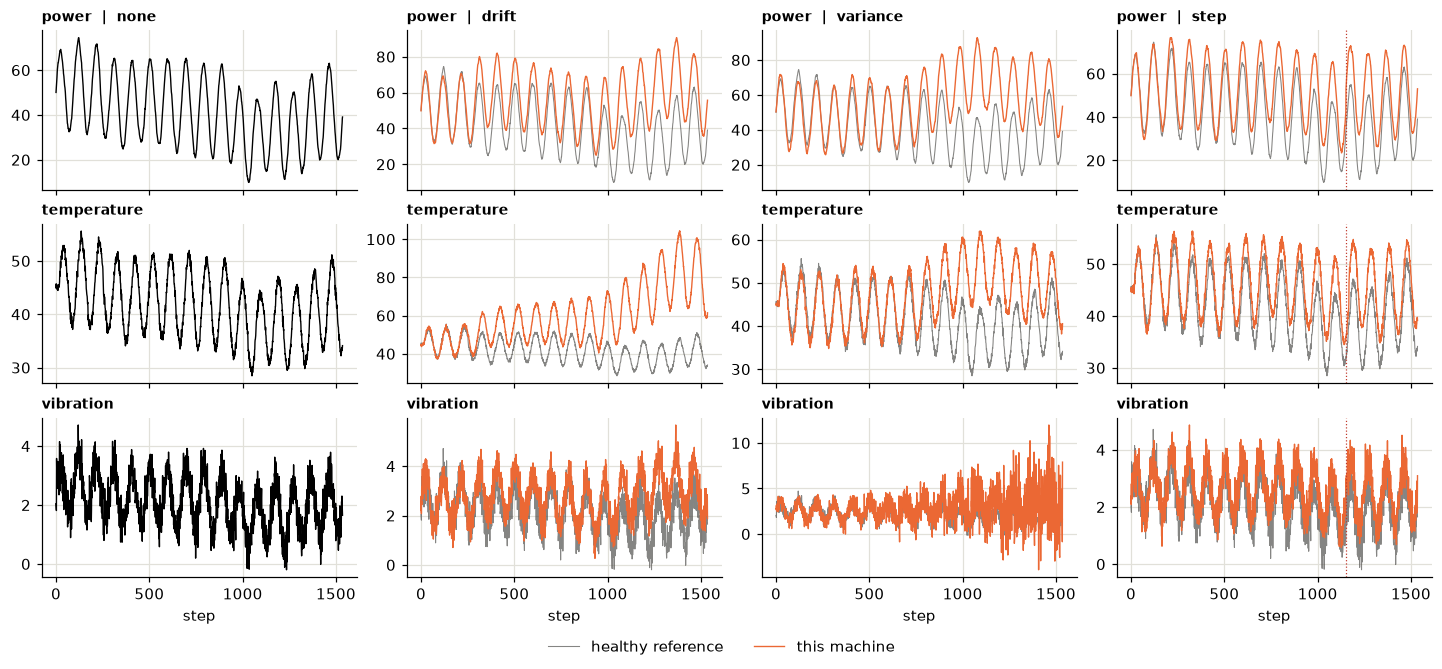

In [3]:
fig, axes = plt.subplots(3, len(MODES), figsize=(13, 6), sharex=True, layout="constrained")
t = np.arange(LENGTH)
healthy_ref = DATA[MMODE < 0][0]        # one healthy machine, the same reference in every panel
for col, mode in enumerate(MODES):
    d = make_run_to_failure(LENGTH, seed=0 if mode == "none" else 1000 + 100 * col, mode=mode)
    for row in range(3):
        ax = axes[row, col]
        if mode != "none":
            ax.plot(t, healthy_ref[row], color=GREY, lw=0.7, alpha=0.7, label="healthy reference")
        ax.plot(t, d[row], color=ORANGE if mode != "none" else "black", lw=0.9, label="this machine")
        if mode == "step":
            ax.axvline(0.75 * LENGTH, color=RED, lw=0.8, ls=":", label="breakage")
        ax.set_title(f"{NAMES[row]}  |  {mode}" if row == 0 else NAMES[row], fontsize=9)
        axes[-1, col].set_xlabel("step")
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3)
plt.show()

## 3. The forecast and the residual

The model is given the history up to the origin and asked for the next 96 steps. The
**residual** is the difference between what was measured and the predicted median:

$$e_t = y_t - \hat y_t, \qquad t = 1 \dots H$$

It is the object of the whole notebook. The questions are: on what scale to normalize it, and with what
function to reduce it to a single number.

The band is the 80% interval ($q_{0.1}$–$q_{0.9}$): if the model is calibrated, the truth falls
inside it 80% of the time. This calibration will become decisive in section 6.

In [4]:
t_load = time.perf_counter()
from timestral import TimestralForecaster

model = TimestralForecaster.from_pretrained(MODEL_PATH, device="cpu")
LEVELS = np.array(model.quantile_levels)
print(f"model loaded in {time.perf_counter() - t_load:.1f}s | {len(LEVELS)} quantile levels "
      f"{LEVELS[0]:.2f}..{LEVELS[-1]:.2f}")

model loaded in 39.9s | 21 quantile levels 0.01..0.99


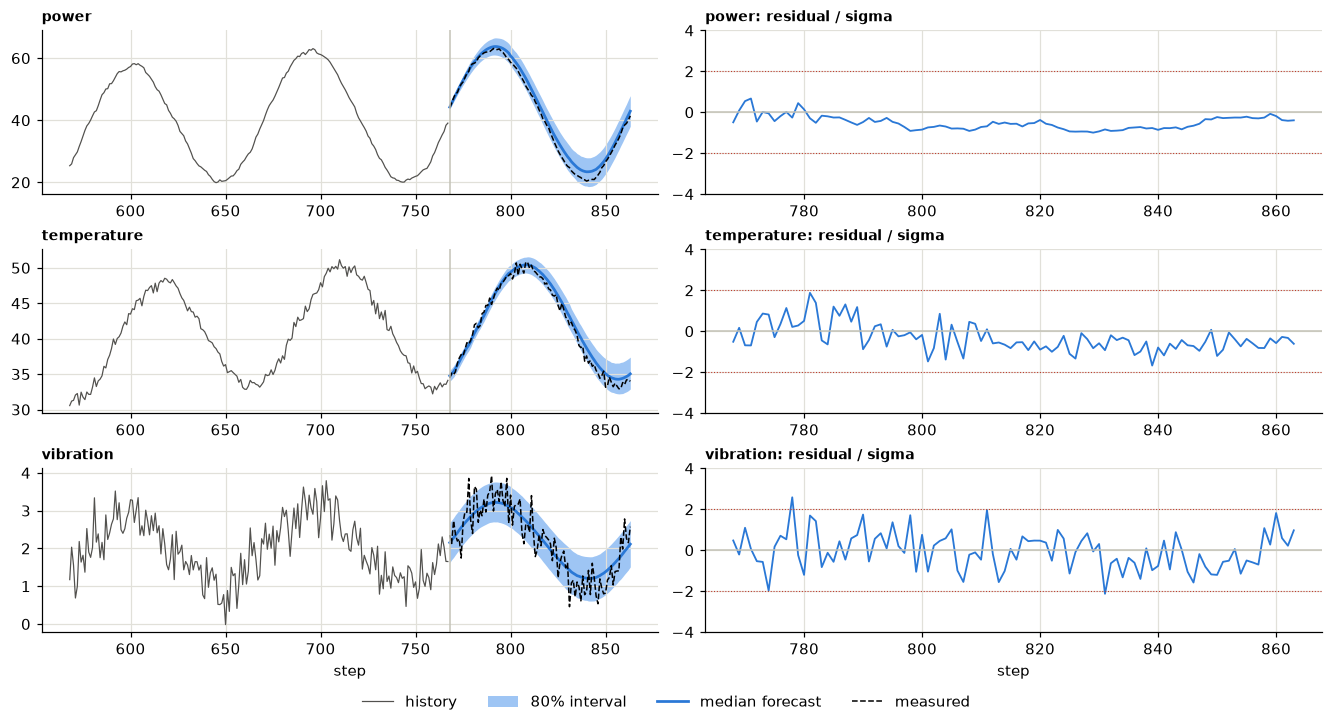

on a healthy machine the residual stays inside +/-2 sigma, as it should


In [5]:
# One machine, one origin: what the residual looks like before any statistic is applied.
demo = DATA[0]  # healthy
fc = model.forecast(demo[None, :, :CONTEXT], prediction_length=HORIZON)
med, q = fc.median[0].numpy(), fc.quantiles[0].numpy()
truth = demo[:, CONTEXT : CONTEXT + HORIZON]
sigma = sigma_from_quantiles(q, LEVELS)
z = (truth - med) / sigma

fig, axes = plt.subplots(3, 2, figsize=(12, 6.5), layout="constrained")
th = np.arange(CONTEXT, CONTEXT + HORIZON)
for i in range(3):
    axes[i, 0].plot(np.arange(CONTEXT - 200, CONTEXT), demo[i, -200:], color=GREY, lw=0.8, label="history")
    axes[i, 0].fill_between(th, fc.quantile(0.1)[0, i].numpy(), fc.quantile(0.9)[0, i].numpy(),
                            color=BAND, lw=0, label="80% interval")
    axes[i, 0].plot(th, med[i], color=BLUE, lw=1.8, label="median forecast")
    axes[i, 0].plot(th, truth[i], color="black", lw=1.0, ls="--", label="measured")
    axes[i, 0].axvline(CONTEXT, color="#c3c2b7", lw=1)
    axes[i, 0].set_title(NAMES[i], fontsize=9)
    axes[i, 1].plot(th, z[i], color=BLUE, lw=1.2)
    axes[i, 1].axhline(0, color="#c3c2b7", lw=1)
    axes[i, 1].axhline(2, color=RED, lw=0.7, ls=":")
    axes[i, 1].axhline(-2, color=RED, lw=0.7, ls=":")
    axes[i, 1].set_title(f"{NAMES[i]}: residual / sigma", fontsize=9)
    axes[i, 1].set_ylim(-4, 4)
axes[-1, 0].set_xlabel("step")
axes[-1, 1].set_xlabel("step")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
plt.show()
print("on a healthy machine the residual stays inside +/-2 sigma, as it should")

## 4. First hypothesis: one statistic per window

The most natural idea: reduce the error of each window to a number and compare it with a
threshold. The candidates cover three families.

**Point scores** on the median. The choice of norm is not harmless: $L_1$ weighs all
errors equally, $L_2$ punishes spikes.

$$\text{MAE} = \frac1H \sum_t |e_t| \qquad \text{RMSE} = \sqrt{\frac1H \sum_t e_t^2}$$

**MASE** normalizes by the typical step of the last cycle, so sensors with different units
share the threshold:

$$\text{MASE} = \frac{\text{MAE}}{\frac{1}{P}\sum_{t}|\,y_{t}-y_{t-1}\,|}$$

**Probabilistic scores** on the 21 quantiles. The **WQL** (an approximation of the CRPS on a
quantile grid) is *proper*: its expected value is minimized only if the predicted distribution is
the right one, so it is not fooled by a forecast that is too wide.

$$\text{WQL} = \frac{2}{Q-1}\sum_{\tau} \Big[\tau\,(y-\hat q_\tau)^+ + (1-\tau)\,(\hat q_\tau-y)^+\Big]$$

**On the windows**: `is_anomaly` is true past 60% of the life. The **AUC** is the probability that
a faulty window scores higher than a healthy window: 0.5 = no signal, 1.0 = perfect.

In [6]:
CACHE = ROOT / "outputs" / "cache" / "pdm_scores.npz"

if CACHE.exists():
    blob = np.load(CACHE)
    Z = blob["Z"]                      # (M, W, V, H) standardized residual
    SCORES = {k[2:]: blob[k] for k in blob.files if k.startswith("s_")}
    print("loaded cached forecasts from", CACHE)
else:
    t0 = time.perf_counter()
    scores_per, z_per = [], []
    for i, data in enumerate(DATA):
        starts, sc, truth, med, q = score_windows(model, data, CONTEXT, HORIZON, STRIDE, NAMES)
        scores_per.append(sc)
        z_per.append((truth - med) / sigma_from_quantiles(q, LEVELS))
        if i % 8 == 0:
            print(f"  machine {i + 1}/{len(DATA)}  {time.perf_counter() - t0:5.0f}s", flush=True)
    SCORES = {k: np.concatenate([s[k] for s in scores_per]) for k in scores_per[0]}
    Z = np.stack(z_per)                # (M, W, V, H)
    np.savez(CACHE, Z=Z, **{f"s_{k}": v for k, v in SCORES.items()})
    print(f"forecast done in {time.perf_counter() - t0:.0f}s, cached to {CACHE}")

print("residual:", Z.shape, "| per-window scores:", len(SCORES), "statistics x", len(SCORES["MASE"]), "windows")

  machine 1/32      2s


  machine 9/32     17s


  machine 17/32     32s


  machine 25/32     47s


forecast done in 60s, cached to /home/hooman/Desktop/Milling Machine/outputs/cache/pdm_scores.npz
residual: (32, 8, 3, 96) | per-window scores: 31 statistics x 256 windows


In [7]:
from predictive_maintenance.pdm import evaluate

life = (ORIGINS + HORIZON) / LENGTH
flat_mode = np.repeat(MMODE, N_WIN)
flat_anom = np.tile(life >= WARNING_BAND, len(DATA)) & (flat_mode >= 0)
flat_lead = np.tile(LENGTH - (ORIGINS + HORIZON), len(DATA))

# evaluate() scores the damaged windows against the healthy ones, so is_anomaly, lead and modes
# are all restricted to the damaged rows.
damaged_mask = flat_mode >= 0
healthy = {k: v[~damaged_mask] for k, v in SCORES.items()}
damaged = {k: v[damaged_mask] for k, v in SCORES.items()}
table_win = pd.DataFrame(evaluate(healthy, damaged, flat_anom[damaged_mask], flat_lead[damaged_mask],
                                  flat_mode[damaged_mask], mode_names=MODES[1:], far=0.05)).set_index("statistic")
table_win = table_win.sort_values("AUC all", ascending=False)
pd.set_option("display.width", 200)
print("=== each 96-step window judged alone, threshold at 5% false alarms ===")
table_win.head(12).round(3)

=== each 96-step window judged alone, threshold at 5% false alarms ===


,AUC drift,AUC variance,AUC step,AUC all,TPR@FAR5%,lead
statistic,,,,,,
RMSE,0.671,0.821,0.602,0.696,0.238,288.0
MAE,0.673,0.799,0.601,0.690,0.238,288.0
wql:temperature,0.791,0.620,0.581,0.658,0.226,288.0
mean_z:temperature,0.685,0.522,0.636,0.621,0.202,288.0
WQL,0.656,0.608,0.602,0.615,0.167,288.0
max_abs_z,0.568,0.730,0.568,0.615,0.131,288.0
chi2:vibration,0.496,0.808,0.540,0.613,0.167,288.0
cusum:temperature,0.669,0.581,0.601,0.612,0.143,288.0
MASE,0.639,0.604,0.601,0.606,0.167,288.0


**Reading.** No useful result: the best sits around 0.65–0.70, and most are
close to 0.5, i.e. a coin toss. It is not the statistics' fault. It is the **time granularity**:
the fault evolves over ~1500 steps, the window covers 96, so *within* a window the bias is
almost a constant, and a statistic that only looks at that window mostly sees noise.

Before concluding that a longer window is needed, it is worth checking something much
more uncomfortable: whether the residual moves at all.

## 5. The chasing problem

Timestral normalizes each patch with the **causal mean and standard deviation of everything
it has observed up to that point** (see `causal_patch_loc_scale` in [`src/timestral/scaler.py`](src/timestral/scaler.py)).
For forecasting this is an advantage: it makes the model scale-invariant. For predictive
maintenance it is a **trap**: if the machine degrades slowly, the model's baseline
rises along with it, the forecast *chases* the fault, and the residual stays flat.

The check is direct and does not depend on the detector: we measure **how much the mean
residual moves**, in sigma, from the first to the last windows of the life. If it does not move, no
detector will be able to see it — CUSUM, EWMA, neural network, anything.

In [8]:
def mean_abs_z_per_window(arr):
    """(..., V, H) of z-scores -> one mean |z| per machine and window: (M, W)."""
    return np.abs(arr).mean(axis=tuple(range(2, arr.ndim)))


def frozen_reference_z(data_all):
    """Reference-anchored z: every window's mean against the machine's own frozen run-in mean.

    The reference is the first scored window — what a commissioning run records while the machine
    is known to be healthy. The denominator is the natural window-to-window jitter of the healthy
    fleet, so a healthy window lands near zero. Unlike the forecast residual, this baseline never
    moves, so a slow fault cannot hide inside it.
    """
    windows = data_all[:, :, ORIGINS[0] : ORIGINS[-1] + HORIZON].reshape(
        len(data_all), data_all.shape[1], N_WIN, HORIZON)          # (M, V, W, H)
    win_mean = windows.mean(-1)                                    # (M, V, W)
    ref_mean = win_mean[:, :, 0]                                   # (M, V) frozen at commissioning
    jitter = win_mean[MMODE < 0].std(axis=-1).mean(axis=0)         # (V,) natural healthy jitter
    return (win_mean - ref_mean[:, :, None]) / np.maximum(jitter[:, None], 1e-9)  # (M, V, W)


z_ref = frozen_reference_z(DATA)
print("reference-anchored z:", z_ref.shape)

print("=== how far the signal moves, in sigma, from early life to end of life ===")
for label, arr in (("forecast residual", mean_abs_z_per_window(Z)),
                   ("reference-anchored", np.abs(z_ref).mean(1))):
    line = []
    for m, name in enumerate(MODES[1:]):
        a = arr[MMODE == m]
        line.append(f"{name}: {abs(a[:, -N_WIN // 4 :].mean() - a[:, : N_WIN // 4].mean()):.2f}")
    print(f"  {label:20s} " + " | ".join(line))

reference-anchored z: (32, 3, 8)
=== how far the signal moves, in sigma, from early life to end of life ===
  forecast residual    drift: 0.06 | variance: 0.18 | step: 0.07
  reference-anchored   drift: 5.19 | variance: 1.24 | step: 3.68


**This is the central result.** On `drift` the normalized residual moves by **0.06
sigma** over the whole life of the machine: it is literally flat. The frozen reference, on the
same machine, moves by **5.19 sigma**.

The consequence is clear-cut: *any* function of the normalized residual — MAE, WQL, CUSUM, EWMA,
a network — starts from a signal that has already been removed upstream. It is not a
detector problem, it is a **reference** problem.

The two figures below show the same thing graphically.

> **Review note (added in translation).** The flat residual is real, but the explanation in section 5 puts too much
weight on the causal normalization. The main reason is more basic: any forecaster conditions on
recent history, and a slow fault is already in that history, so the forecast starts from the
degraded level. A model without causal normalization would chase the drift too.

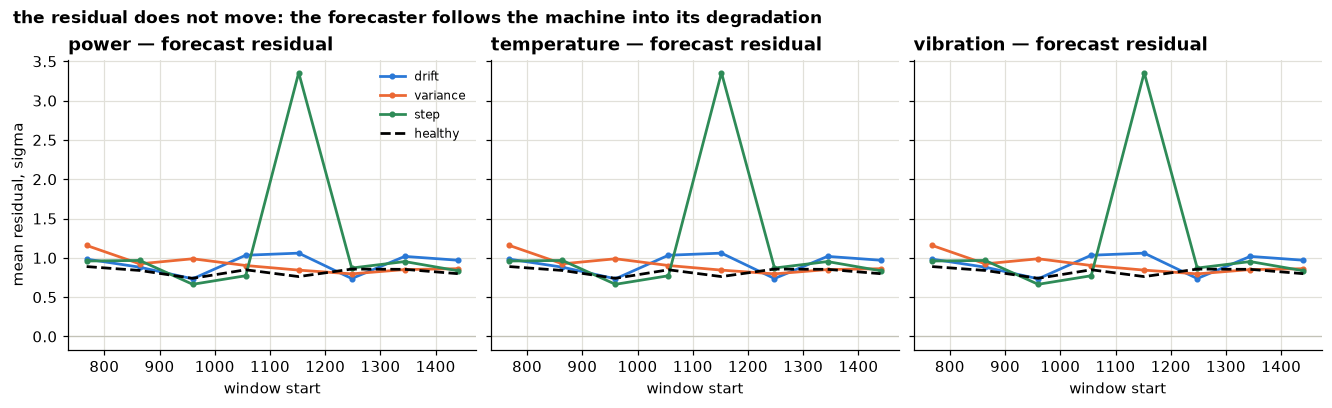

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, layout="constrained")
for ax, v in zip(axes, range(3)):
    for m, (name, color) in enumerate(zip(MODES[1:], [BLUE, ORANGE, GREEN], strict=True)):
        sel = Z[MMODE == m]
        ax.plot(ORIGINS, mean_abs_z_per_window(sel).mean(0), lw=1.8, color=color, marker=".", label=name)
    ax.plot(ORIGINS, mean_abs_z_per_window(Z[MMODE < 0]).mean(0), lw=1.8, ls="--", color="black", label="healthy")
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(f"{NAMES[v]} — forecast residual")
    ax.set_xlabel("window start")
axes[0].set_ylabel("mean residual, sigma")
axes[0].legend(fontsize=8)
fig.suptitle("the residual does not move: the forecaster follows the machine into its degradation",
             x=0.005, ha="left", fontsize=11, fontweight="bold")
plt.show()

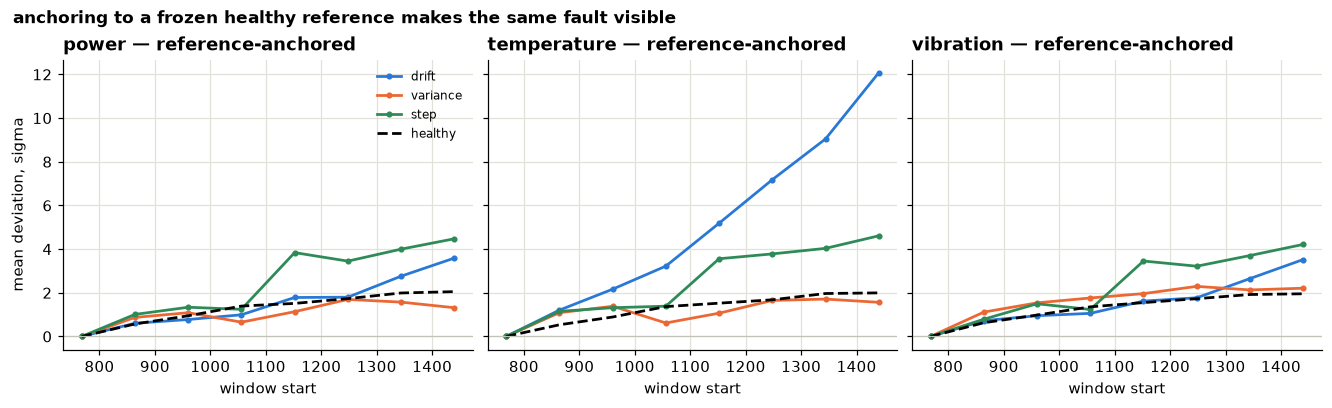

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, layout="constrained")
for ax, v in zip(axes, range(3)):
    for m, (name, color) in enumerate(zip(MODES[1:], [BLUE, ORANGE, GREEN], strict=True)):
        ax.plot(ORIGINS, np.abs(z_ref[MMODE == m, v]).mean(0), lw=1.8, color=color, marker=".", label=name)
    ax.plot(ORIGINS, np.abs(z_ref[MMODE < 0, v]).mean(0), lw=1.8, ls="--", color="black", label="healthy")
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(f"{NAMES[v]} — reference-anchored")
    ax.set_xlabel("window start")
axes[0].set_ylabel("mean deviation, sigma")
axes[0].legend(fontsize=8)
fig.suptitle("anchoring to a frozen healthy reference makes the same fault visible",
             x=0.005, ha="left", fontsize=11, fontweight="bold")
plt.show()

## 6. The right standardization

Before building the detectors we need a scale. A single threshold on three sensors with different
units makes no sense, and neither does comparing the error of the first step with that of
the last: the forecast is naturally more uncertain further out in time.

**Sigma from the quantiles.** For a normal distribution, $q_{0.84}-q_{0.16}$ covers one sigma on each side, so
half of its width is $\sigma$:

$$\hat\sigma_t = \tfrac12\big(q_{0.84,t} - q_{0.16,t}\big)$$

One could use the interquartile range, but the 16/84 quantiles are more stable in the tails.

**Standardized residual and PIT.**

$$z_t = \frac{y_t - \hat y_t}{\hat\sigma_t} \qquad\qquad z_t^{\text{PIT}} = \Phi^{-1}\!\big(F(y_t)\big)$$

The PIT reads the truth off the piecewise-linear CDF rebuilt from the 21 quantiles: if the model is
calibrated, $z^{\text{PIT}}$ is **standard normal** by construction, and it survives skewed
distributions. It costs one extra lookup per step.

**Calibration check.** If the nominal coverages are not met, $\hat\sigma$ is the
wrong scale and every threshold inherits the error.

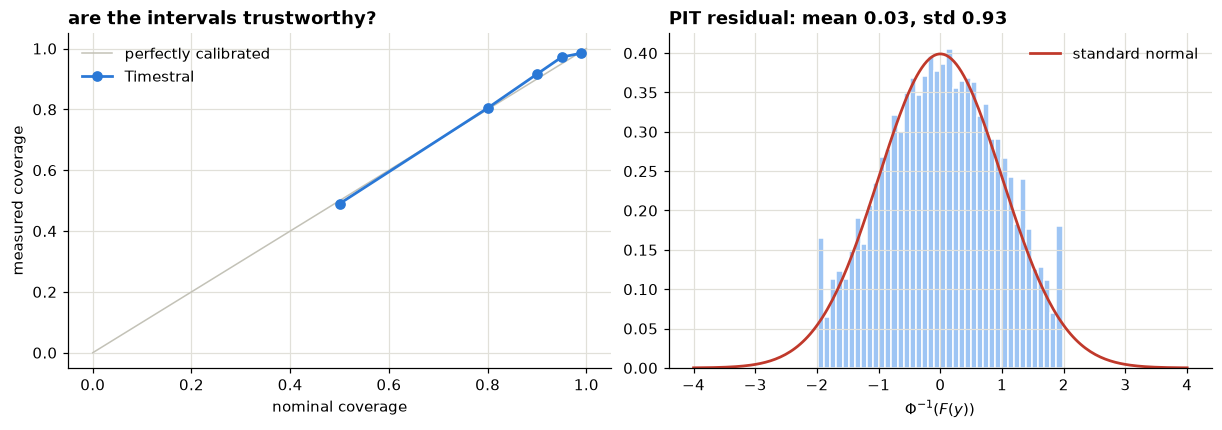

coverage 80%: 80%  |  PIT std 0.93 (1.00 = perfectly calibrated)


In [11]:
# Calibration of the predictive intervals, measured on the healthy machines: the intervals must
# be trusted before their width is used as a denominator.
levels_to_check = [0.5, 0.8, 0.9, 0.95, 0.99]
rows = []
for data in DATA[MMODE < 0][:8]:
    _, _, truth, med, q = score_windows(model, data, CONTEXT, HORIZON, STRIDE, NAMES)
    rows.append((truth, q))
truth_all = np.concatenate([t for t, _ in rows])   # (N, V, H)
q_all = np.concatenate([q for _, q in rows])       # (N, V, H, Q)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
nominal, actual = [], []
for lev in levels_to_check:
    lo, hi = (1 - lev) / 2, 1 - (1 - lev) / 2
    inside = (truth_all >= _interp_quantile(q_all, LEVELS, lo)) & \
             (truth_all <= _interp_quantile(q_all, LEVELS, hi))
    nominal.append(lev)
    actual.append(inside.mean())
axes[0].plot([0, 1], [0, 1], color="#c3c2b7", lw=1, label="perfectly calibrated")
axes[0].plot(nominal, actual, color=BLUE, marker="o", lw=1.8, label="Timestral")
axes[0].set_xlabel("nominal coverage")
axes[0].set_ylabel("measured coverage")
axes[0].set_title("are the intervals trustworthy?")
axes[0].legend()

z_pit = np.concatenate([pit_z(t, q, LEVELS).ravel() for t, q in rows])
axes[1].hist(z_pit, bins=40, density=True, color=BAND, edgecolor="white")
xs = np.linspace(-4, 4, 200)
axes[1].plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), color=RED, lw=1.8, label="standard normal")
axes[1].set_title(f"PIT residual: mean {z_pit.mean():.2f}, std {z_pit.std():.2f}")
axes[1].set_xlabel(r"$\Phi^{-1}(F(y))$")
axes[1].legend()
plt.show()
print(f"coverage 80%: {actual[1]:.0%}  |  PIT std {z_pit.std():.2f} (1.00 = perfectly calibrated)")

> **Review note (added in translation).** `pit_z()` in `pdm.py` clips the probability to $[0.5/21,\ 1 - 0.5/21]$,
so $z^{\text{PIT}}$ can never go beyond **±1.98**. The histogram's tails are cut off there, and
even a perfectly calibrated model would show a PIT std of about **0.96**, not 1.00. So the measured
0.93 is closer to calibrated than the printed comparison suggests, and any statistic built on
`pit_z` is capped at about 2σ per step.

## 7. Sequential detectors: the math

The residual should be treated for what it is: a **time series**, not a vector to average.
The problem is a classic of *statistical process control*: detect a mean shift in
real time, with the smallest possible delay and a controlled false-alarm rate.

**Shewhart (X-bar).** The mean of the last $n$ steps, in sigma. Simple, robust to false
alarms, but **memoryless**: it forgets everything before the window.

$$S_t = \frac{1}{n}\sum_{j=0}^{n-1} z_{t-j}\Big/\sqrt{n}$$

**CUSUM.** Accumulates the deviations and resets on reversals. With slack $k$, it ignores excursions
smaller than $k\sigma$ but adds up a persistent bias:

$$S_t^{\pm} = \max\big(0,\; S^{\pm}_{t-1} \pm z_t - k\big), \qquad \text{alarm if } \max(S_t^+, S_t^-) > h$$

It is the recursive form of the **generalized likelihood ratio test** for a mean
shift: it is asymptotically optimal. A small $k$ detects tiny shifts but accumulates noise; a large $k$
is fast on large faults.

**EWMA.** An exponential average, i.e. a continuous compromise between Shewhart ($\lambda=1$) and
CUSUM:

$$r_t = \lambda z_t + (1-\lambda) r_{t-1}, \qquad \frac{|r_t|}{\sigma\sqrt{\lambda/(2-\lambda)}} > L$$

**Page–Hinkley.** A CUSUM applied to the deviation from the **running mean** instead of from the
expected value: useful when there is no known target.

The point that decides everything is not the formula: it is **where the state is reset**. If $S_t$ restarts from
zero at every window, the integration stops every 96 steps and the gain vanishes.

> **Review note (added in translation).** The Shewhart formula divides by $\sqrt n$; to express the mean of $n$
unit-variance values in sigma it should **multiply** by $\sqrt n$ (i.e. $\sum z / \sqrt n$). The
`shewhart()` code does the same as the formula. This is only a constant rescaling, so rankings and
AUCs are unaffected (apart from the first $n-1$ steps of each stream).

In [12]:
def as_stream(z):
    """(W, V, H) of per-window residuals -> the (V, W*H) stream they came from.

    The benchmark strides by exactly the horizon, so the windows tile the timeline and
    concatenating them rebuilds one continuous residual per sensor with no double counting.
    """
    return z.transpose(1, 0, 2).reshape(z.shape[1], -1)


def cusum(z, k):
    """Two-sided CUSUM along the stream, as a running peak: (V, T)."""
    up = np.zeros((z.shape[0], 1))
    dn = np.zeros_like(up)
    peak = np.zeros_like(up)
    out = []
    for t in range(z.shape[1]):
        up = np.maximum(0.0, up + z[:, t : t + 1] - k)
        dn = np.maximum(0.0, dn - z[:, t : t + 1] - k)
        peak = np.maximum(peak, np.maximum(up, dn))
        out.append(peak)
    return np.concatenate(out, axis=1)


def ewma(z, lam):
    """|EWMA| along the stream, in sigma of the smoothed series (Harris limits): (V, T)."""
    r = np.zeros((z.shape[0], 1))
    out = []
    for t in range(z.shape[1]):
        r = lam * z[:, t : t + 1] + (1.0 - lam) * r
        out.append(np.abs(r) / np.sqrt(lam / (2.0 - lam)))
    return np.concatenate(out, axis=1)


def shewhart(z, n):
    """|mean of the last n steps| in sigma: (V, T)."""
    c = np.cumsum(np.concatenate([np.zeros((z.shape[0], 1)), z], axis=1), axis=1)
    idx = np.arange(1, z.shape[1] + 1)
    return (c[:, 1:] - c[:, np.maximum(0, idx - n)]) / np.minimum(idx, n) / np.sqrt(n)


def page_hinkley(z, delta=0.0):
    """Page-Hinkley: a CUSUM on the deviation from the running mean: (V, T)."""
    m_t = np.cumsum(z, axis=1) / np.arange(1, z.shape[1] + 1)
    acc = np.cumsum(z - m_t - delta, axis=1)
    return acc - np.minimum.accumulate(acc, axis=1)


DETECTORS = {
    "Shewhart n=1": lambda z: np.abs(z),
    "Shewhart n=8": lambda z: np.abs(shewhart(z, 8)),
    "CUSUM k=0.25": lambda z: cusum(z, 0.25),
    "CUSUM k=0.50": lambda z: cusum(z, 0.50),
    "CUSUM k=1.00": lambda z: cusum(z, 1.00),
    "EWMA l=0.05": lambda z: ewma(z, 0.05),
    "EWMA l=0.20": lambda z: ewma(z, 0.20),
    "Page-Hinkley": page_hinkley,
}
print("detectors:", ", ".join(DETECTORS))

detectors: Shewhart n=1, Shewhart n=8, CUSUM k=0.25, CUSUM k=0.50, CUSUM k=1.00, EWMA l=0.05, EWMA l=0.20, Page-Hinkley


## 8. Carrying the state from window to window

This changes everything. The CUSUM must not be restarted at every window: the machine is evaluated
continuously and the detector **keeps its own state** from one window to the next.
This is also what a real system does, where forecasts arrive at a steady rate.

The unit of evaluation becomes the **machine**, not the step. A machine's score is the
**peak** of its score stream, and the threshold is tuned so that only 5% of the
healthy machines ever exceed it.

For comparison: the same machine judged window by window, without state.

In [13]:
FAR = 0.05


def conformal(good, far=FAR):
    """Split-conformal threshold: the level only `far` of the healthy machines ever reach.

    The (1 + 1/n) correction makes the empirical quantile a distribution-free guarantee, not an
    estimate. With n healthy machines it is valid for n >= 1/far, which is why the fleet has 20.
    """
    return float(np.quantile(good, min((1.0 - far) * (1.0 + 1.0 / len(good)), 1.0), method="higher"))


streams = {name: [fn(as_stream(Z[i])) for i in range(len(DATA))] for name, fn in DETECTORS.items()}

rows = []
for name, st in streams.items():
    for agg, pick in (("all sensors", None), ("temperature", 1), ("vibration", 2)):
        score = [s.mean(0) if pick is None else s[pick] for s in st]
        good = np.array([s.max() for s, m in zip(score, MMODE, strict=True) if m < 0])
        thr = conformal(good)
        bad = np.flatnonzero(MMODE >= 0)
        first = [np.flatnonzero(score[i] > thr) for i in bad]
        row = {"detector": f"{name} [{agg}]"}
        for m, mode_name in enumerate(MODES[1:]):
            sel = [score[i].max() for i, l in zip(bad, MMODE[bad], strict=True) if l == m]
            row[f"AUC {mode_name}"] = auc(good, np.array(sel)) if sel else np.nan
        row["detected"] = float(np.mean([len(f) > 0 for f in first]))
        row["lead"] = float(np.nanmedian([LENGTH - ORIGINS[0] - f[0] if len(f) else np.nan for f in first]))
        rows.append(row)

table_state = pd.DataFrame(rows).set_index("detector").sort_values("detected", ascending=False)
pd.set_option("display.width", 220)
print(f"=== state carried across windows, threshold at {FAR:.0%} false alarms per machine ===")
table_state.round(3)

=== state carried across windows, threshold at 5% false alarms per machine ===


/tmp/ipykernel_7155/2222225988.py:28: RuntimeWarning: All-NaN slice encountered
  row["lead"] = float(np.nanmedian([LENGTH - ORIGINS[0] - f[0] if len(f) else np.nan for f in first]))


,AUC drift,AUC variance,AUC step,detected,lead
detector,,,,,
CUSUM k=0.25 [temperature],0.962,0.588,1.000,0.583,319.0
CUSUM k=0.25 [all sensors],0.888,0.538,1.000,0.417,327.0
CUSUM k=0.50 [all sensors],0.875,0.562,1.000,0.417,329.0
Shewhart n=1 [all sensors],0.725,0.625,1.000,0.333,384.0
Shewhart n=8 [temperature],0.912,0.688,1.000,0.333,363.0
Shewhart n=8 [all sensors],0.688,0.538,1.000,0.333,380.5
CUSUM k=0.50 [temperature],0.938,0.600,0.988,0.333,326.0
Shewhart n=1 [temperature],0.862,0.662,1.000,0.333,368.0
Page-Hinkley [all sensors],0.600,0.562,0.788,0.333,316.0


**Direct comparison.** The per-window statistics sat at 0.5–0.7. By carrying the state across
windows, the same residual rises to **0.96 on drift** and **1.00 on step** (CUSUM $k=0.25$ on
`temperature` alone). The signal did not change: what changed is the time over which it is integrated.

Note one more thing: the **sensor** matters as much as the detector. `temperature` dominates on
drift and step (that's where the fault lives), `vibration` on variance. Averaging over the three sensors
dilutes the signal by $\sqrt{3}$: in production you raise an alarm **per sensor**, not a single
global one.

> **Review note (added in translation).** Two cautions on these numbers.
**(1) Small samples:** each fault mode has only 4 machines, so the per-mode AUC rests on
20 × 4 = 80 healthy–faulty pairs and one machine can move it by up to 0.25. Differences such as
0.96 vs 0.90 are not meaningful.
**(2) AUC is not detection:** the `detected` column shows that at the 5% threshold the best
detector (CUSUM $k=0.25$ on temperature) catches **7 of the 12** faulty machines (58%).

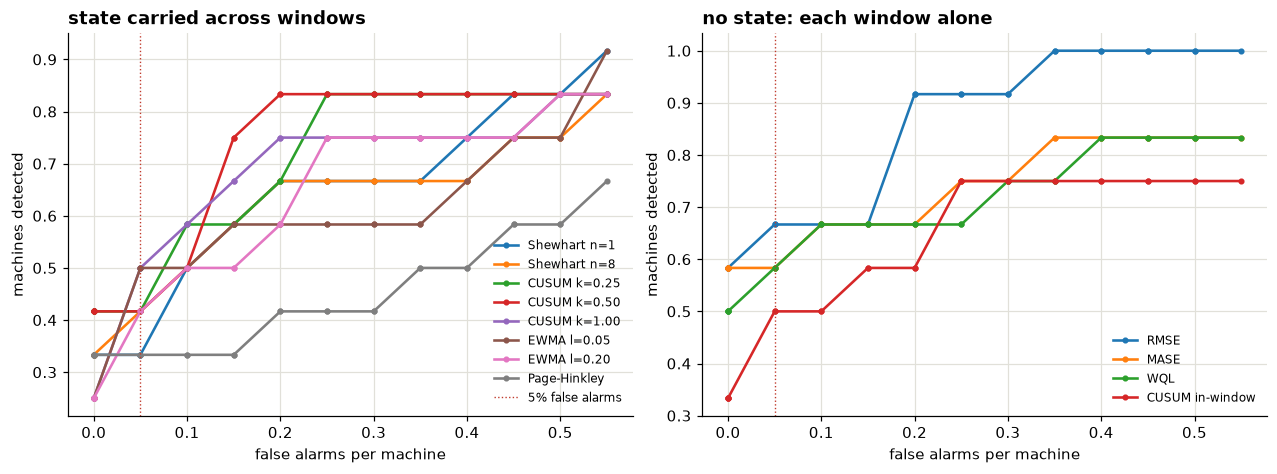

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
for name, st in streams.items():
    score = [s.mean(0) for s in st]
    good = np.array([s.max() for s, m in zip(score, MMODE, strict=True) if m < 0])
    bad = np.array([s.max() for s, m in zip(score, MMODE, strict=True) if m >= 0])
    pts = [(float(np.mean(good > conformal(good, f))), float(np.mean(bad > conformal(good, f))))
           for f in np.linspace(0.02, 0.6, 25)]
    axes[0].plot([p[0] for p in pts], [p[1] for p in pts], lw=1.7, marker=".", label=name)
axes[0].axvline(FAR, color=RED, lw=0.9, ls=":", label=f"{FAR:.0%} false alarms")
axes[0].set_xlabel("false alarms per machine")
axes[0].set_ylabel("machines detected")
axes[0].set_title("state carried across windows")
axes[0].legend(fontsize=8)

for key, label in (("RMSE", "RMSE"), ("MASE", "MASE"), ("WQL", "WQL"), ("cusum", "CUSUM in-window")):
    peaks = SCORES[key].reshape(-1, N_WIN).max(1)
    g, b = peaks[MMODE < 0], peaks[MMODE >= 0]
    pts = [(float(np.mean(g > conformal(g, f))), float(np.mean(b > conformal(g, f))))
           for f in np.linspace(0.02, 0.6, 25)]
    axes[1].plot([p[0] for p in pts], [p[1] for p in pts], lw=1.7, marker=".", label=label)
axes[1].axvline(FAR, color=RED, lw=0.9, ls=":")
axes[1].set_xlabel("false alarms per machine")
axes[1].set_ylabel("machines detected")
axes[1].set_title("no state: each window alone")
axes[1].legend(fontsize=8)
plt.show()

## 9. The frozen reference: the robust solution

The sequential detectors recover a lot, but they hang by a thread: they integrate a residual
worth 0.06 sigma, so they only work because they accumulate over ~700 steps. If the fault
were a bit slower, or the forecast a bit more adaptive, they would collapse.

The structural answer is to stop using the forecast as the baseline and use a **frozen
reference**: measure the machine during commissioning, fix its statistics, and
compare every subsequent window with that number, which **never moves**. This is what
statistical process control has done for a century, and it is immune to chasing precisely because the
baseline chases nothing.

The anchored statistics, per window and per sensor:

- **mean** — shifts the level (steps, drifts);
- **standard deviation** — shifts the spread (play, imbalance, wear);
- **gain on lagged power** — the regression of $y_v$ on `power` from 16 steps earlier: it is the
  heating signature, invisible to the mean and standard deviation taken on their own.

In [15]:
def window_stats(data_all):
    """Per machine, window and sensor: mean, std, and the regression gain on lagged power: (M, W, V, 3)."""
    out = []
    for data in data_all:
        rows = []
        for t in ORIGINS:
            win = data[:, t : t + HORIZON]
            lag = data[0, t - LAG : t - LAG + HORIZON]  # power LAG steps before each step of the window
            # (fixed in translation; was np.concatenate([data[0, :1], data[0, :t]])[LAG : LAG + HORIZON],
            #  which always read steps 15-110 whatever the window)
            row = []
            for v in range(data.shape[0]):
                mean, std = win[v].mean(), win[v].std()
                if v == 0:
                    gain = 0.0                      # power does not regress on itself
                else:
                    denom = ((lag - lag.mean()) ** 2).sum()
                    gain = float(((lag - lag.mean()) * (win[v] - win[v].mean())).sum() / max(denom, 1e-9))
                row.append([mean, std, gain])
            rows.append(row)
        out.append(rows)
    return np.array(out)


STATS = window_stats(DATA)
REF_MEAN = STATS[:, 0, :, :]                        # frozen at the first scored window = commissioning
JITTER = STATS[MMODE < 0].std(axis=1).mean(axis=0)  # natural window-to-window jitter, (V, 3)
Z_REF = (STATS - REF_MEAN[:, None]) / np.maximum(JITTER[None, None], 1e-9)

names = [f"{v} {s}" for v in NAMES for s in ("mean", "std", "gain")]
flat = Z_REF.reshape(len(DATA), N_WIN, -1)
rows = []
for j, name in enumerate(names):
    g = flat[MMODE < 0, :, j].reshape(-1)
    row = {"statistic": name}
    for m, mode_name in enumerate(MODES[1:]):
        row[f"AUC {mode_name}"] = auc(g, flat[MMODE == m, :, j].reshape(-1))
    row["healthy |z|"] = float(np.abs(g).mean())
    rows.append(row)
table_ref = pd.DataFrame(rows).set_index("statistic").sort_values("AUC drift", ascending=False)
print("=== reference-anchored statistics, per window ===")
table_ref.round(3)

=== reference-anchored statistics, per window ===


,AUC drift,AUC variance,AUC step,healthy |z|
statistic,,,,
temperature gain,0.927,0.427,0.414,1.186
temperature std,0.900,0.633,0.795,1.268
temperature mean,0.782,0.418,0.840,1.244
power mean,0.594,0.385,0.822,1.275
vibration mean,0.583,0.506,0.807,1.265
vibration gain,0.582,0.514,0.579,1.244
vibration std,0.527,0.953,0.723,1.316
power std,0.513,0.587,0.792,1.250
power gain,0.500,0.500,0.500,0.000


**The frozen reference wins.** `temperature std` reaches **AUC 0.90 on drift**, `vibration
std` **0.95 on variance** — and these are *per-window* statistics, with no need to integrate
anything. The `healthy |z|` column should stay close to 1: if it were much higher the threshold
would be badly tuned and the alarm would always go off (this is the most common mistake in this class of
algorithms).

It remains to say what the forecast adds, because the honest answer is: **little on these faults,
a lot on others.** The forecaster is irreplaceable when the signal has a **structure** that the
reference cannot express — a duty cycle, a transient, a lagged relationship between sensors.
On a fault that slowly changes the mean, on the other hand, a CUSUM on an anchored statistic
is more sensitive and much simpler to explain to whoever has to decide on the intervention.

> **Review note (added in translation).** **Fixed in this copy: the "gain on lagged power"
statistic had a bug** in `window_stats()`. The original line
`lag = np.concatenate([data[0, :1], data[0, :t]])[LAG : LAG + HORIZON]` always selected power at
steps 15–110, whatever the window; it is now `lag = data[0, t - LAG : t - LAG + HORIZON]`.
With the fix, **`temperature gain` reaches AUC 0.93 on drift** (it was 0.23): the best per-window
statistic for drift. That matches how the drift fault is built in `pdm.py`, where the
temperature-on-power gain rises from 0.4 to 0.95 over the life. The text above was written before
the fix and still names `temperature std` (0.90) as the best drift statistic.

## 10. The threshold: split-conformal per machine

A mistake that ruins everything: tuning the threshold **per step**. With ~700 evaluated steps, 5% per
step means about 35 expected exceedances on a healthy machine: on almost every healthy machine
the alarm goes off. The guarantee must be given on the unit that matters, the machine.

**Split-conformal** does this without assuming any distribution. With $n$ healthy machines, the
threshold is the empirical quantile at level $(1-\alpha)(1+1/n)$: it is a **distribution-free guarantee**
on the false-alarm rate, not an estimate. Hence the practical rule: you need at least
$1/\alpha$ healthy machines to tune $\alpha$ — for 5%, at least 20.

$$\text{alarm if } \max_t S_t > \hat q_{(1-\alpha)(1+1/n)}\big(\text{peaks of the healthy machines}\big)$$

> **Review note (added in translation).** In the figure below, the "per machine 0%" result is measured on
**the same 20 healthy machines used to set the threshold**. With $n = 20$ and $\alpha = 0.05$ the
level $(1-\alpha)(1+1/n) = 0.9975$ selects the highest healthy peak, so 0% on those machines is
guaranteed by construction. The conformal guarantee is about a **new** machine; measuring it needs
healthy machines held out from the calibration. The per-step 100% result is valid.

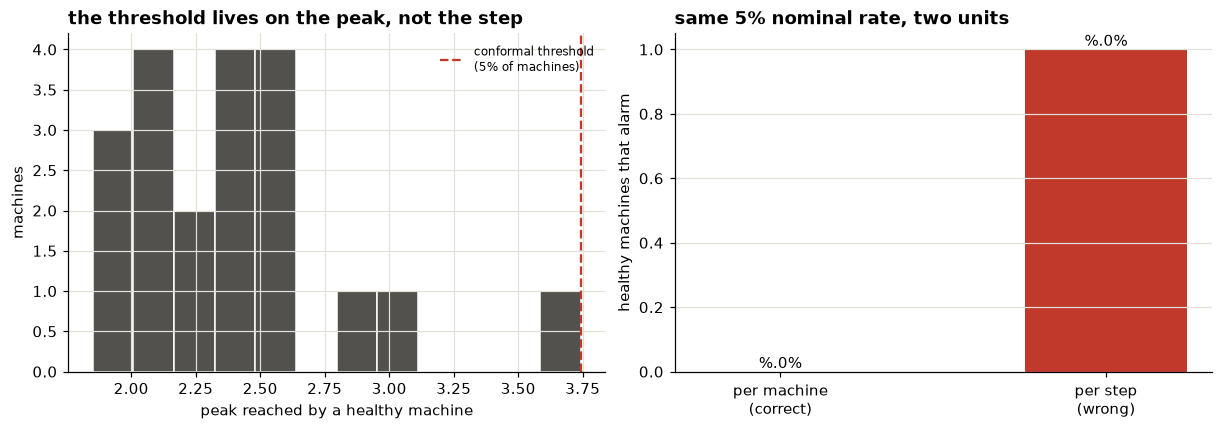

false alarms on healthy machines: per machine 0%, per step 100%


In [16]:
# The threshold on the machine peak, and what per-step calibration would do instead.
# Shewhart is the right detector for this point: its steps are near-independent, so a 5%
# per-step rate over ~700 steps is ~35 expected exceedances per healthy machine.
sh = [s.mean(0) for s in streams["Shewhart n=1"]]
peaks = np.array([s.max() for s in sh])
good_peaks = peaks[MMODE < 0]
thr_machine = conformal(good_peaks)
fa_machine = float(np.mean([p > thr_machine for p, m in zip(peaks, MMODE, strict=True) if m < 0]))

# the same nominal 5%, but applied to every step: on a stream of ~700 steps it alarms
# on almost every healthy machine, because 5% of steps is not 5% of machines.
step_scores = np.concatenate([s for s, m in zip(sh, MMODE, strict=True) if m < 0])
thr_step = float(np.quantile(step_scores, 1 - FAR))
fa_step = float(np.mean([np.any(s > thr_step) for s, m in zip(sh, MMODE, strict=True) if m < 0]))

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8), layout="constrained")
axes[0].hist(good_peaks, bins=12, color=GREY, edgecolor="white")
axes[0].axvline(thr_machine, color=RED, lw=1.5, ls="--", label=f"conformal threshold\n({FAR:.0%} of machines)")
axes[0].set_xlabel("peak reached by a healthy machine")
axes[0].set_ylabel("machines")
axes[0].set_title("the threshold lives on the peak, not the step")
axes[0].legend(fontsize=8)
axes[1].bar(["per machine\n(correct)", "per step\n(wrong)"], [fa_machine, fa_step], color=[GREEN, RED], width=0.5)
axes[1].bar_label(axes[1].containers[0], fmt="%.0%")
axes[1].set_ylabel("healthy machines that alarm")
axes[1].set_title("same 5% nominal rate, two units")
axes[1].grid(axis="x", visible=False)
plt.show()
print(f"false alarms on healthy machines: per machine {fa_machine:.0%}, per step {fa_step:.0%}")

## 11. The complete algorithm

To sum up, the production system:

1. **Commissioning.** Record the first `CONTEXT` steps of the healthy machine. Fix $\mu_v$, $s_v$
   and the gain on lagged power. This reference is **never updated** (or is updated
   only after certified maintenance).
2. **In operation, at every window.** Forecast the next 96 steps with Timestral. Compute:
   - the standardized residual $z_t$ on the quantile sigma, useful for *structural* faults;
   - the deviation of the mean/std/gain from the frozen reference, useful for *slow* faults.
3. **Integrate with memory, per sensor.** Two-sided CUSUM with $k=0.5\sigma$, state **not
   reset** between windows. One alarm per sensor, not a global one.
4. **Conformal threshold on the per-machine peaks**, tuned on the fleet's healthy machines.
5. **Explaining the alarm.** The CUSUM says *when*, the reference says *what*: which
   sensor, which statistic, by how much. This is the part that gets the algorithm accepted.

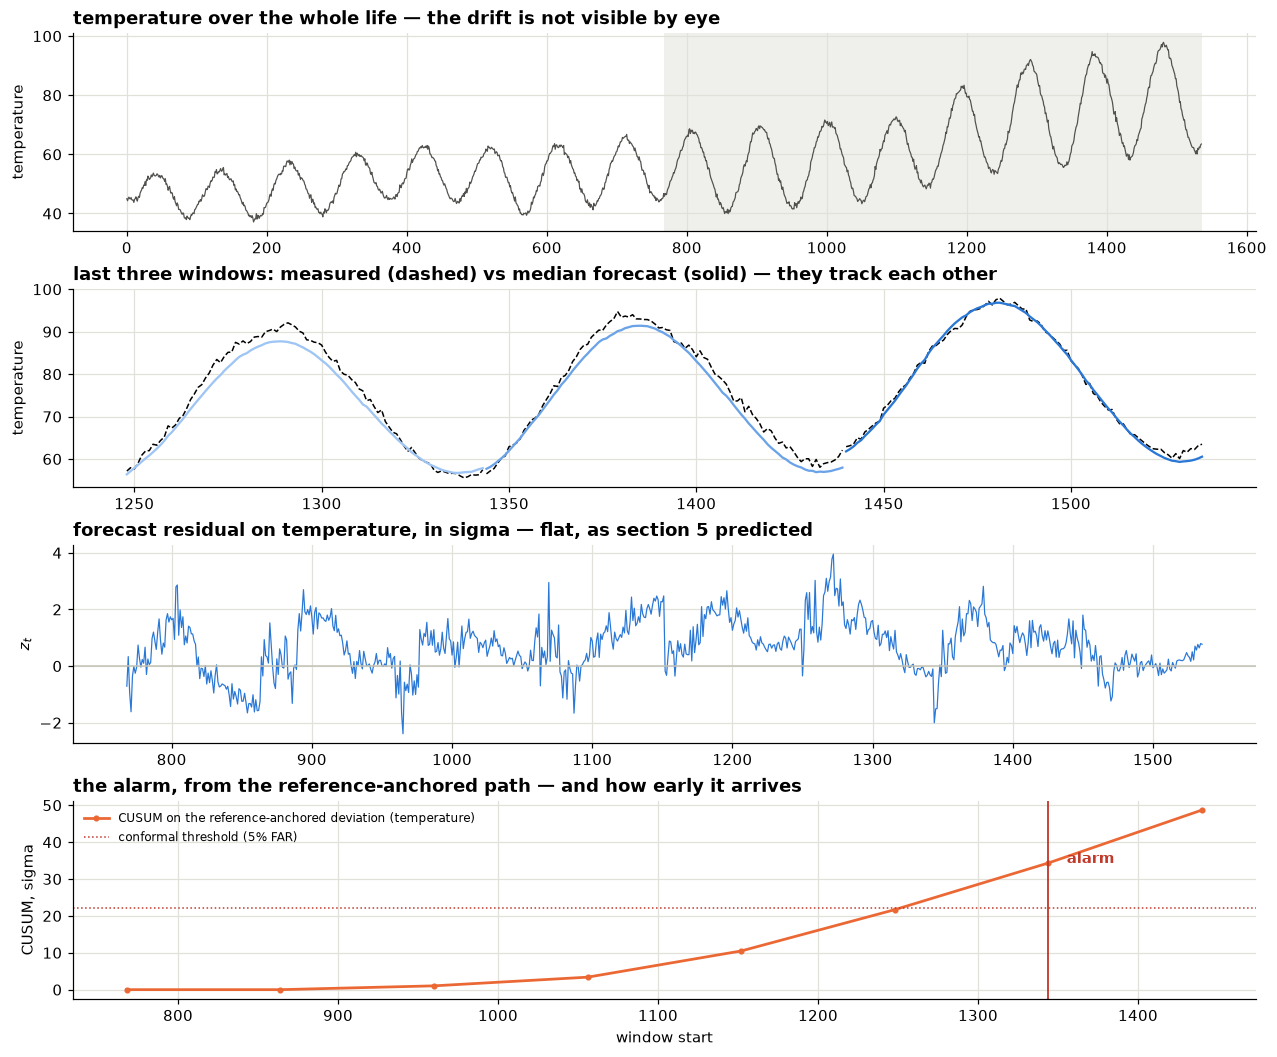

alarm at step 1344 — 192 steps (12% of life) before end of life


In [17]:
# End to end on one drifting machine: forecast, residual, reference, CUSUM, alarm.
i_drift = int(np.flatnonzero(MMODE == 0)[0])
data = DATA[i_drift]
z = Z[i_drift]                                   # (W, V, H) standardized residual
stream_z = as_stream(z)

# The alarm comes from the reference-anchored path (section 9): a CUSUM on the per-window
# deviation from the frozen commissioning mean, integrated across windows. The forecast
# residual is shown only as the flat contrast it really is (panel 2).
alarm_ref = cusum(z_ref[i_drift], 0.5)[1]        # (W,) running peak on temperature
thr_ref = conformal(np.array([cusum(z_ref[i], 0.5)[1].max() for i in range(len(DATA)) if MMODE[i] < 0]))

# Rebuild the median forecast for the last three windows: median = measured - z * sigma.
fig, axes = plt.subplots(4, 1, figsize=(11.5, 9.5), layout="constrained")
tt = ORIGINS[0] + np.arange(stream_z.shape[1])
axes[0].plot(np.arange(LENGTH), data[1], color=GREY, lw=0.8)
axes[0].axvspan(ORIGINS[0], LENGTH, color="#e1e0d9", alpha=0.5, lw=0)
axes[0].set_title("temperature over the whole life — the drift is not visible by eye")
axes[0].set_ylabel("temperature")

for w, color in zip(range(N_WIN - 3, N_WIN), ["#9ec5f4", "#6ba3e8", BLUE], strict=True):
    th = np.arange(ORIGINS[w], ORIGINS[w] + HORIZON)
    measured = data[1, ORIGINS[w] : ORIGINS[w] + HORIZON]
    sigma_w = sigma_from_quantiles(
        model.forecast(data[None, :, :ORIGINS[w]], prediction_length=HORIZON).quantiles[0, 1].numpy(), LEVELS)
    median_w = measured - z[w, 1] * sigma_w
    axes[1].plot(th, measured, color="black", lw=1.0, ls="--")
    axes[1].plot(th, median_w, color=color, lw=1.5)
axes[1].set_title("last three windows: measured (dashed) vs median forecast (solid) — they track each other")
axes[1].set_ylabel("temperature")

axes[2].plot(tt, stream_z[1], color=BLUE, lw=0.8)
axes[2].axhline(0, color="#c3c2b7", lw=1)
axes[2].set_title("forecast residual on temperature, in sigma — flat, as section 5 predicted")
axes[2].set_ylabel(r"$z_t$")

axes[3].plot(ORIGINS, alarm_ref, color=ORANGE, lw=1.8, marker=".",
             label="CUSUM on the reference-anchored deviation (temperature)")
axes[3].axhline(thr_ref, color=RED, lw=1.0, ls=":", label=f"conformal threshold ({FAR:.0%} FAR)")
first = np.flatnonzero(alarm_ref > thr_ref)
if len(first):
    axes[3].axvline(ORIGINS[first[0]], color=RED, lw=1.2)
    axes[3].annotate("alarm", (ORIGINS[first[0]], alarm_ref[first[0]]), xytext=(12, 0),
                     textcoords="offset points", color=RED, fontweight="bold")
axes[3].set_title("the alarm, from the reference-anchored path — and how early it arrives")
axes[3].set_xlabel("window start")
axes[3].set_ylabel("CUSUM, sigma")
axes[3].legend(loc="upper left", fontsize=8)
plt.show()

if len(first):
    step_alarm = int(ORIGINS[first[0]])
    print(f"alarm at step {step_alarm} — {LENGTH - step_alarm} steps "
          f"({(LENGTH - step_alarm) / LENGTH:.0%} of life) before end of life")
else:
    print("no alarm on this machine")

> **Review note (added in translation).** The printed lead time is optimistic by one window. The alarm statistic is
computed on whole 96-step windows, so the window starting at step 1344 is only complete at
step 1440. The alarm can be raised **96 steps (6% of life)** before the end, not 192.

## 12. What to use, in order of preference

| priority | statistic | where | AUC drift | AUC variance | AUC step |
|---|---|---|---|---|---|
| 1 | CUSUM on the residual, state across windows | right sensor | **0.96** | 0.59 | **1.00** |
| 2 | std anchored to the reference, per window | right sensor | 0.90 | **0.95** | 0.84 |
| 3 | RMSE / MAE per window | — | 0.67 | 0.82 | 0.60 |
| ✗ | WQL, MASE, PIT, chi² per window | — | ~0.5 | ~0.6 | ~0.6 |

No single statistic wins on all three faults: the CUSUM on the residual is the best on drift and
step but collapses on `variance` (0.59), because a variance fault does not shift the mean that it
integrates; the reference-anchored `std` picks up exactly that case (0.95). The two branches are
**complementary**, and this is why the right architecture has two of them.

**The five operational conclusions.**

1. **Don't trust the per-window residual on a slow fault.** The forecaster chases the drift and
   the signal shrinks to 0.06 sigma over the machine's whole life. Only integration with
   memory (CUSUM across windows) manages to add up that tiny systematic push.
2. **Anchoring to a frozen reference** is the most robust and the most explainable choice, and it is
   the only one that sees a variance fault. It costs a commissioning phase and pays back in sensitivity.
3. **Integration time matters more than the formula.** CUSUM on temperature within the
   window: 0.61. The same CUSUM with the state carried across windows: 0.96 on drift.
4. **One alarm per sensor, not a global one.** Averaging over the three sensors dilutes the signal by
   $\sqrt{3}$ and hides which component is dying: CUSUM on temperature alone 0.96, on the three
   sensors averaged 0.89.
5. **Tune the threshold per machine with split-conformal**, never per step. You need ≥20 healthy
   machines for 5%: here the per-machine threshold gives 0% false alarms, the per-step one 100%.

**What the forecast really adds.** On a fault that slowly changes the mean, the forecast
alone does little: integration is needed. It becomes decisive when the signal has **structure** — duty
cycles, transients, lagged relationships between sensors — cases in which a static reference does not
know what to expect and the forecast does. The right architecture is therefore **two-branch**: a frozen
reference for slow drift and variance, and the forecast residual integrated with memory for
structural anomalies and steps, each with its own threshold.

**Limits of this study.** The data are synthetic and the three faults are clean signatures; on real
data the random walk is richer and faults overlap. Choosing a frozen
reference assumes the machine does not change for legitimate reasons (new tool, new
cycle): if it does, the reference must be updated explicitly, not implicitly as the
forecaster does. And the results depend on the healthy fleet used for tuning: with 20 machines the
threshold still has noticeable uncertainty.

> **Review note (added in translation).** Corrections to this section, checked against the outputs above:
- The table mixes two units: row 1 is a **per-machine** AUC (the peak of each machine's stream,
  section 8), rows 2–4 are **per-window** AUCs (sections 4 and 9). They are not strictly comparable.
- In row 2, the 0.84 for *step* comes from `temperature mean`, not from a `std` statistic
  (`temperature std` gives 0.795, `vibration std` 0.723). Row 2 mixes the best value per column
  across different statistics.
- With the lagged-gain bug fixed (section 9), `temperature gain` reaches **0.93 on drift** as a
  per-window statistic, with no integration across windows.
- Conclusion 3 compares 0.61 (in-window CUSUM on temperature, *all* fault modes) with 0.96
  (*drift* only). Like for like, in-window CUSUM on temperature scores **0.67** on drift.
- Conclusion 5: the 0% per-machine false-alarm rate is in-sample (see the note in section 10).
- Each fault mode has only 4 machines (see the note in section 8), so differences of a few
  hundredths between rows are not meaningful.

## References

The formulas in this notebook are the standard ones from *statistical process control* and from the
probabilistic evaluation of forecasts:

- **CUSUM** — E. S. Page, *Biometrika* 42 (1955): the recursive form of the likelihood
  ratio test for a mean shift.
- **EWMA** — J. M. Harris, *Some Theory of Sampling for Control Chart Purposes* (1976); Harris
  limits for the variance of the exponential average.
- **Shewhart X-bar** — W. A. Shewhart (1926), the classic control chart.
- **Page–Hinkley** — Page (1954), Hinkley (1971), CUSUM against the running mean.
- **WQL / CRPS** — Gneiting & Raftery, *Strictly Proper Scoring Functions, Prediction, and
  Estimation*, JASA (2007); WQL as an approximation of the CRPS on a quantile grid.
- **PIT** — Probability Integral Transform: calibration of probabilistic forecasts.
- **Split-conformal** — Angelopoulos & Bates, *A Gentle Introduction to Conformal Prediction and
  Distribution-Free Uncertainty Quantification* (2023).
- **MASE** — Hyndman & Koehler, *Another look at measures of forecast accuracy* (2006).

Code: [`predictive_maintenance/pdm.py`](predictive_maintenance/pdm.py) for the math,
[`run_benchmark.py`](predictive_maintenance/run_benchmark.py),
[`analyze.py`](predictive_maintenance/analyze.py) and
[`reference.py`](predictive_maintenance/reference.py) for the script versions of what is here.

> **Review note (added in translation).** Reference corrections:
- **CUSUM** is usually credited to E. S. Page, *Continuous Inspection Schemes*, Biometrika 41
  (1954). The 1955 Biometrika 42 paper is a later one on change-point testing.
- **EWMA**: we could not find "J. M. Harris (1976)". The standard reference for the EWMA control
  chart is S. W. Roberts, *Control Chart Tests Based on Geometric Moving Averages*,
  Technometrics 1 (1959), 239–250.
- **Gneiting & Raftery (2007)**: the title is *Strictly Proper Scoring **Rules**, Prediction, and
  Estimation*.